QPSK mapping validation
---------------------------------------------
Input bits: (0, 0) | Symbol: +0.707+0.707j | Detected: (np.int64(0), np.int64(0))
Input bits: (0, 1) | Symbol: -0.707+0.707j | Detected: (np.int64(0), np.int64(1))
Input bits: (1, 1) | Symbol: -0.707-0.707j | Detected: (np.int64(1), np.int64(1))
Input bits: (1, 0) | Symbol: +0.707-0.707j | Detected: (np.int64(1), np.int64(0))

BPSK validation
Input: 0, Symbol: 1, Detected: 0
Input: 1, Symbol: -1, Detected: 1

Differential encoding validation
Input bits:      [0 1 1 0 1]
Encoded symbols: [ 1.+0.j  1.+0.j -1.-0.j  1.+0.j  1.+0.j -1.-0.j]
Detected bits:   [0 1 1 0 1]
Validation PASS: True


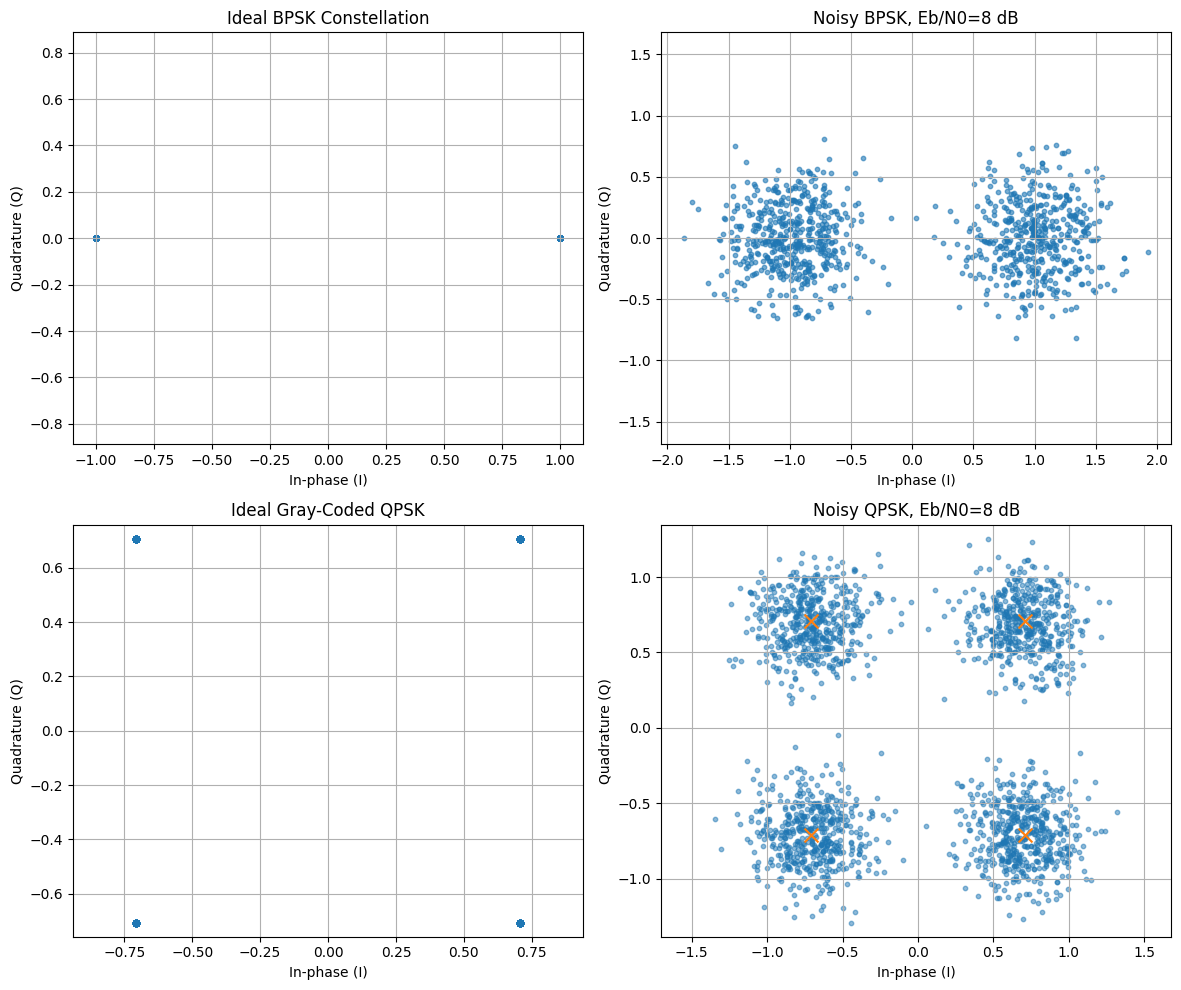

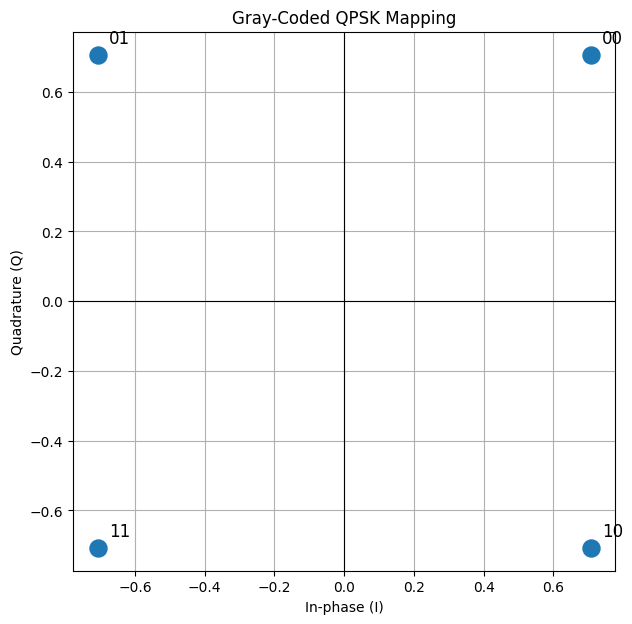

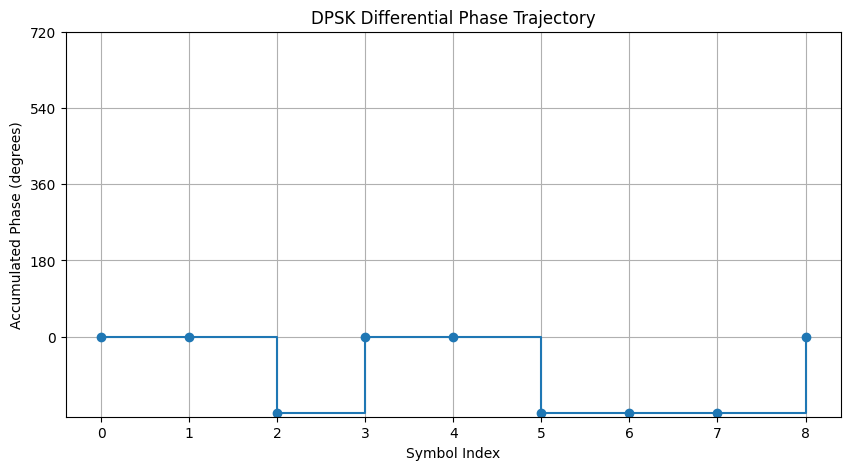

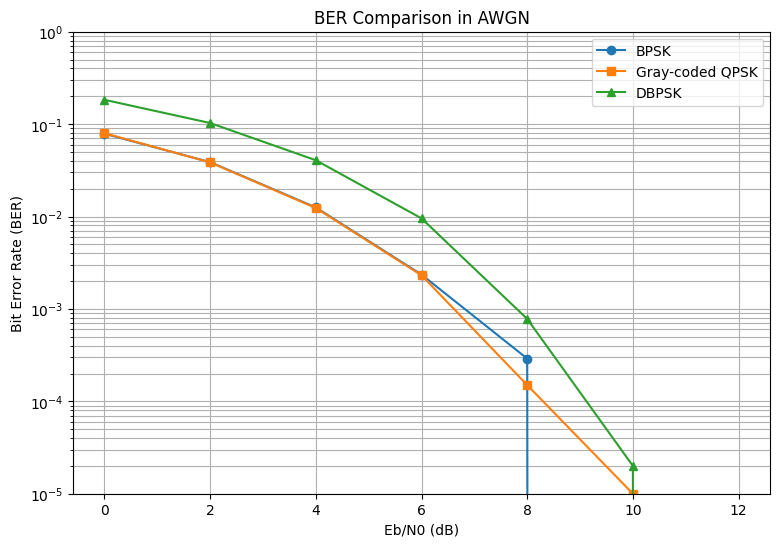

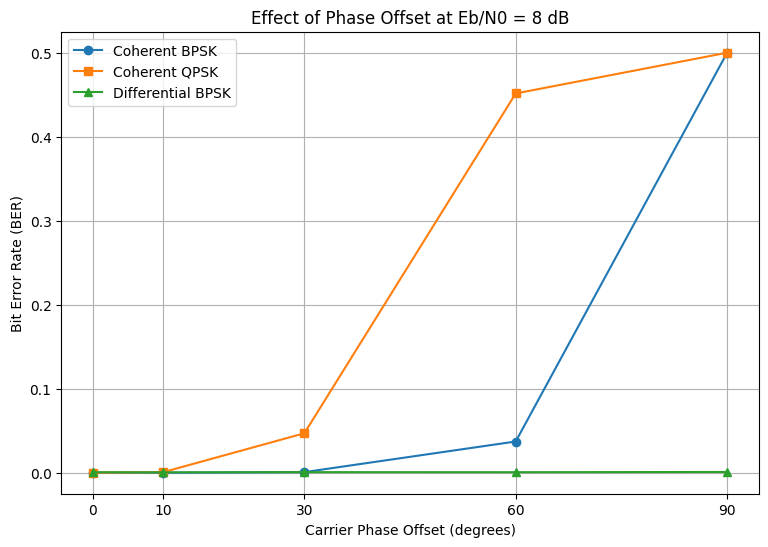


BER at Eb/N0 = 8 dB
---------------------------------------------
BPSK BER: 0.00019
QPSK BER: 0.00029
DBPSK BER: 0.00085

Phase-offset decision statistics
Offset | BPSK BER | QPSK BER | DBPSK BER
  0 deg | 0.000330 | 0.000240 | 0.000820
 10 deg | 0.000240 | 0.001010 | 0.000710
 30 deg | 0.000930 | 0.047180 | 0.000930
 60 deg | 0.037390 | 0.451510 | 0.000880
 90 deg | 0.499820 | 0.499990 | 0.001120


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# EXPERIMENT 10: BPSK, GRAY-CODED QPSK AND DPSK
# ============================================================

np.random.seed(42)

# Simulation parameters
N_BITS = 100_000
SNR_DB = 8
SNR_RANGE_DB = np.arange(0, 13, 2)
PHASE_OFFSETS_DEG = [0, 10, 30, 60, 90]

# ============================================================
# 1. COMMON FUNCTIONS
# ============================================================

def add_awgn(signal, ebn0_db, bits_per_symbol=1):
    """
    Add complex AWGN.
    Signal has unit average symbol energy.
    Eb/N0 is specified in dB.
    """
    ebn0 = 10 ** (ebn0_db / 10)
    noise_variance = 1 / (
        2 * bits_per_symbol * ebn0
    )

    noise = np.sqrt(noise_variance) * (
        np.random.randn(len(signal))
        + 1j * np.random.randn(len(signal))
    )

    return signal + noise


def calculate_ber(tx_bits, rx_bits):
    return np.mean(tx_bits != rx_bits)


# ============================================================
# 2. BPSK MODULATION AND COHERENT DETECTION
# ============================================================

def bpsk_modulate(bits):
    # Bit 0 -> +1, Bit 1 -> -1
    return 1 - 2 * bits


def bpsk_demodulate(received):
    # Coherent detection using the real-axis decision boundary
    return (np.real(received) < 0).astype(int)


# ============================================================
# 3. GRAY-CODED QPSK MODULATION AND DETECTION
# ============================================================

# Mapping:
# 00 -> 45 degrees
# 01 -> 135 degrees
# 11 -> 225 degrees
# 10 -> 315 degrees

QPSK_MAP = {
    (0, 0): np.exp(1j * np.pi / 4),
    (0, 1): np.exp(1j * 3 * np.pi / 4),
    (1, 1): np.exp(1j * 5 * np.pi / 4),
    (1, 0): np.exp(1j * 7 * np.pi / 4)
}

QPSK_BITS = np.array([
    [0, 0],
    [0, 1],
    [1, 1],
    [1, 0]
])

QPSK_SYMBOLS = np.array([
    QPSK_MAP[tuple(bits)] for bits in QPSK_BITS
])


def qpsk_modulate(bits):
    # Two bits form one QPSK symbol
    bit_pairs = bits.reshape(-1, 2)
    return np.array([
        QPSK_MAP[tuple(pair)] for pair in bit_pairs
    ])


def qpsk_demodulate(received):
    # Minimum Euclidean-distance detector
    distances = np.abs(
        received[:, None] - QPSK_SYMBOLS[None, :]
    ) ** 2

    detected_indices = np.argmin(distances, axis=1)

    return QPSK_BITS[detected_indices].reshape(-1)


# ============================================================
# 4. DIFFERENTIAL ENCODING AND DBPSK DETECTION
# ============================================================

def differential_encode(bits):
    """
    Bit 0 -> no phase change
    Bit 1 -> phase change of pi

    The first transmitted symbol is the reference.
    """
    symbols = np.zeros(len(bits) + 1, dtype=complex)
    symbols[0] = 1 + 0j

    for k, bit in enumerate(bits):
        if bit == 0:
            symbols[k + 1] = symbols[k]
        else:
            symbols[k + 1] = -symbols[k]

    return symbols


def dpsk_demodulate(received):
    # Compare consecutive received symbols
    differential_products = (
        received[1:] * np.conj(received[:-1])
    )

    # Negative real part indicates a phase change of pi
    return (
        np.real(differential_products) < 0
    ).astype(int)


# ============================================================
# 5. GENERATE RANDOM DATA AND TRANSMIT
# ============================================================

# Even number of bits is required for QPSK
bits = np.random.randint(0, 2, N_BITS)
bits_qpsk = bits[:N_BITS // 2 * 2]

bpsk_tx = bpsk_modulate(bits)
qpsk_tx = qpsk_modulate(bits_qpsk)
dpsk_tx = differential_encode(bits)

# Add AWGN and a carrier phase offset
def simulate_bpsk(phase_deg, ebn0_db):
    phase = np.deg2rad(phase_deg)
    received = add_awgn(
        bpsk_tx * np.exp(1j * phase), ebn0_db, 1
    )
    detected = bpsk_demodulate(received)
    return received, detected


def simulate_qpsk(phase_deg, ebn0_db):
    phase = np.deg2rad(phase_deg)
    received = add_awgn(
        qpsk_tx * np.exp(1j * phase), ebn0_db, 2
    )
    detected = qpsk_demodulate(received)
    return received, detected


def simulate_dpsk(phase_deg, ebn0_db):
    phase = np.deg2rad(phase_deg)
    received = add_awgn(
        dpsk_tx * np.exp(1j * phase), ebn0_db, 1
    )
    detected = dpsk_demodulate(received)
    return received, detected


# ============================================================
# 6. MANDATORY VALIDATION OF QPSK MAPPING
# ============================================================

print("QPSK mapping validation")
print("-" * 45)

for pair in [(0, 0), (0, 1), (1, 1), (1, 0)]:
    symbol = QPSK_MAP[pair]
    detected = qpsk_demodulate(
        np.array([symbol])
    )

    print(
        f"Input bits: {pair} | "
        f"Symbol: {symbol.real:+.3f}"
        f"{symbol.imag:+.3f}j | "
        f"Detected: {tuple(detected)}"
    )

print("\nBPSK validation")
for bit in [0, 1]:
    symbol = bpsk_modulate(np.array([bit]))
    detected = bpsk_demodulate(symbol.astype(complex))
    print(f"Input: {bit}, Symbol: {symbol[0]}, "
          f"Detected: {detected[0]}")

print("\nDifferential encoding validation")
test_bits = np.array([0, 1, 1, 0, 1])
test_symbols = differential_encode(test_bits)
test_detected = dpsk_demodulate(test_symbols)

print("Input bits:     ", test_bits)
print("Encoded symbols:", test_symbols)
print("Detected bits:  ", test_detected)
print("Validation PASS:", np.array_equal(
    test_bits, test_detected
))


# ============================================================
# 7. IDEAL AND NOISY CONSTELLATION DIAGRAMS
# ============================================================

rx_bpsk, det_bpsk = simulate_bpsk(0, SNR_DB)
rx_qpsk, det_qpsk = simulate_qpsk(0, SNR_DB)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].scatter(
    np.real(bpsk_tx[:1000]),
    np.imag(bpsk_tx[:1000]), s=12
)
axes[0, 0].set_title("Ideal BPSK Constellation")
axes[0, 0].set_xlabel("In-phase (I)")
axes[0, 0].set_ylabel("Quadrature (Q)")
axes[0, 0].grid(True)
axes[0, 0].axis("equal")

axes[0, 1].scatter(
    np.real(rx_bpsk[:1000]),
    np.imag(rx_bpsk[:1000]), s=10, alpha=0.6
)
axes[0, 1].set_title(f"Noisy BPSK, Eb/N0={SNR_DB} dB")
axes[0, 1].set_xlabel("In-phase (I)")
axes[0, 1].set_ylabel("Quadrature (Q)")
axes[0, 1].grid(True)
axes[0, 1].axis("equal")

axes[1, 0].scatter(
    np.real(qpsk_tx), np.imag(qpsk_tx), s=20
)
axes[1, 0].set_title("Ideal Gray-Coded QPSK")
axes[1, 0].set_xlabel("In-phase (I)")
axes[1, 0].set_ylabel("Quadrature (Q)")
axes[1, 0].grid(True)
axes[1, 0].axis("equal")

axes[1, 1].scatter(
    np.real(rx_qpsk[:2000]),
    np.imag(rx_qpsk[:2000]), s=10, alpha=0.5
)
axes[1, 1].scatter(
    np.real(QPSK_SYMBOLS),
    np.imag(QPSK_SYMBOLS), marker="x", s=100
)
axes[1, 1].set_title(f"Noisy QPSK, Eb/N0={SNR_DB} dB")
axes[1, 1].set_xlabel("In-phase (I)")
axes[1, 1].set_ylabel("Quadrature (Q)")
axes[1, 1].grid(True)
axes[1, 1].axis("equal")

plt.tight_layout()
plt.show()


# ============================================================
# 8. QPSK MAPPING DIAGRAM WITH BIT LABELS
# ============================================================

plt.figure(figsize=(7, 7))

plt.scatter(
    QPSK_SYMBOLS.real,
    QPSK_SYMBOLS.imag,
    s=150
)

for symbol, pair in zip(QPSK_SYMBOLS, QPSK_BITS):
    plt.annotate(
        "".join(map(str, pair)),
        (symbol.real, symbol.imag),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=12
    )

plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Gray-Coded QPSK Mapping")
plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.grid(True)
plt.axis("equal")
plt.show()


# ============================================================
# 9. PHASE TRAJECTORY
# ============================================================

trajectory_bits = np.array([0, 1, 1, 0, 1, 0, 0, 1])
trajectory_symbols = differential_encode(trajectory_bits)

phase_deg = np.rad2deg(
    np.unwrap(np.angle(trajectory_symbols))
)

plt.figure(figsize=(10, 5))
plt.step(
    np.arange(len(phase_deg)),
    phase_deg,
    where="post",
    marker="o"
)
plt.title("DPSK Differential Phase Trajectory")
plt.xlabel("Symbol Index")
plt.ylabel("Accumulated Phase (degrees)")
plt.yticks([0, 180, 360, 540, 720])
plt.grid(True)
plt.show()


# ============================================================
# 10. BER VS Eb/N0 FOR ALL THREE MODULATIONS
# ============================================================

ber_bpsk = []
ber_qpsk = []
ber_dpsk = []

for snr_db in SNR_RANGE_DB:
    _, det1 = simulate_bpsk(0, snr_db)
    _, det2 = simulate_qpsk(0, snr_db)
    _, det3 = simulate_dpsk(0, snr_db)

    ber_bpsk.append(calculate_ber(bits, det1))
    ber_qpsk.append(calculate_ber(bits_qpsk, det2))
    ber_dpsk.append(calculate_ber(bits, det3))

plt.figure(figsize=(9, 6))
plt.semilogy(
    SNR_RANGE_DB, ber_bpsk, "o-", label="BPSK"
)
plt.semilogy(
    SNR_RANGE_DB, ber_qpsk, "s-", label="Gray-coded QPSK"
)
plt.semilogy(
    SNR_RANGE_DB, ber_dpsk, "^-", label="DBPSK"
)

plt.xlabel("Eb/N0 (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("BER Comparison in AWGN")
plt.grid(True, which="both")
plt.legend()
plt.ylim(1e-5, 1)
plt.show()


# ============================================================
# 11. BER VS CARRIER PHASE OFFSET
# ============================================================

phase_ber_bpsk = []
phase_ber_qpsk = []
phase_ber_dpsk = []

for offset in PHASE_OFFSETS_DEG:
    _, det1 = simulate_bpsk(offset, SNR_DB)
    _, det2 = simulate_qpsk(offset, SNR_DB)
    _, det3 = simulate_dpsk(offset, SNR_DB)

    phase_ber_bpsk.append(calculate_ber(bits, det1))
    phase_ber_qpsk.append(calculate_ber(bits_qpsk, det2))
    phase_ber_dpsk.append(calculate_ber(bits, det3))

plt.figure(figsize=(9, 6))
plt.plot(
    PHASE_OFFSETS_DEG, phase_ber_bpsk,
    "o-", label="Coherent BPSK"
)
plt.plot(
    PHASE_OFFSETS_DEG, phase_ber_qpsk,
    "s-", label="Coherent QPSK"
)
plt.plot(
    PHASE_OFFSETS_DEG, phase_ber_dpsk,
    "^-", label="Differential BPSK"
)

plt.xlabel("Carrier Phase Offset (degrees)")
plt.ylabel("Bit Error Rate (BER)")
plt.title(f"Effect of Phase Offset at Eb/N0 = {SNR_DB} dB")
plt.xticks(PHASE_OFFSETS_DEG)
plt.grid(True)
plt.legend()
plt.show()


# ============================================================
# 12. PRINT DECISION STATISTICS
# ============================================================

print("\nBER at Eb/N0 =", SNR_DB, "dB")
print("-" * 45)

print("BPSK BER:", calculate_ber(
    bits, bpsk_demodulate(
        add_awgn(bpsk_tx, SNR_DB, 1)
    )
))

print("QPSK BER:", calculate_ber(
    bits_qpsk, qpsk_demodulate(
        add_awgn(qpsk_tx, SNR_DB, 2)
    )
))

print("DBPSK BER:", calculate_ber(
    bits, dpsk_demodulate(
        add_awgn(dpsk_tx, SNR_DB, 1)
    )
))

print("\nPhase-offset decision statistics")
print("Offset | BPSK BER | QPSK BER | DBPSK BER")

for i, offset in enumerate(PHASE_OFFSETS_DEG):
    print(
        f"{offset:>3} deg | "
        f"{phase_ber_bpsk[i]:.6f} | "
        f"{phase_ber_qpsk[i]:.6f} | "
        f"{phase_ber_dpsk[i]:.6f}"
    )